# Compare zonal DSE transport across experiments

Collect the saved frequency budgets from **Output/Zonal_energy_transpose**.
Follow the layout and Matplotlib style of **Heating_profiles.ipynb**:
RH increases across columns, with paired original/locked radiation rows
for each qflux. Every panel within a figure shares its axes and scale.

Compare total transport, mean-flow transport, the three frequency contributions,
and total transient transport as longitude-pressure maps. Two bar-plot grids
summarize the signed column-integrated budgets. Positive values indicate
eastward transport and negative values indicate westward transport.

All quantities come from the saved full-record diagnostics. The notebook
does not filter the atmospheric fields or call the analysis scripts.


## Import packages and locate the saved budgets


In [10]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, ScalarFormatter

PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "Code" / "plot_style.mplstyle").is_file()),
    Path("/home/b11209013/Isca_analysis"),
)
DATA_DIR = PROJECT_ROOT / "Output" / "Zonal_energy_transpose"
STYLE_PATH = PROJECT_ROOT / "Code" / "plot_style.mplstyle"


## Load, collect, and validate each experiment

The maps are already integrated over latitude using meridional strip widths.
For the bar plots, use the saved column integrals and average over longitude.
Their units are watts: PW for the overall budget and TW for the transient bands.

The loader checks units, frequency-band definitions, spatial grids, integration
settings, and budget closure. It rejects older latitude-average files with
column units of W/m. Record lengths and averaging dates are retained separately
for each experiment.


In [11]:
files = sorted(DATA_DIR.glob("*_frequency_budget.npz"))
if not files:
    raise FileNotFoundError(f"No *_frequency_budget.npz files found in {DATA_DIR}")

FIELD_NAMES = ("total", "mean_flow", "low", "mid", "high", "transient")
transport_fields = {field: {} for field in FIELD_NAMES}
contributions = {}
experiment_info = {}
source_files = {}
inventory_rows = []
comparison_fields = (
    "column_transport_units", "transport_units", "meridional_reduction",
    "latitude_min", "latitude_max", "planet_radius_m", "meridional_extent_m",
    "height_reference", "column_mass", "frequency_filter", "preprocessing",
    "rd_J_kg_K", "cp_J_kg_K", "gravity_m_s2", "bands",
)

for file in files:
    with np.load(file, allow_pickle=False) as archive:
        name = file.stem.removesuffix("_frequency_budget")
        info = json.loads(archive["metadata"].item())
        if (info.get("column_transport_units") != "W"
                or info.get("transport_units") != "J m2 kg-1 s-1"
                or "meridional_reduction" not in info):
            raise ValueError(f"{file.name}: expected a meridionally integrated budget in W")
        if tuple(archive["component"].tolist()) != ("mean", "low", "mid", "high"):
            raise ValueError(f"Unexpected component ordering in {file.name}")

        pressure = np.asarray(archive["pfull"], dtype=float)
        longitude = np.asarray(archive["lon"], dtype=float)
        mass = np.asarray(archive["layer_mass"], dtype=float)
        terms = np.asarray(archive["transport_terms"], dtype=float)
        direct = np.asarray(archive["mean_flux"], dtype=float)
        transient = np.asarray(archive["transient_flux"], dtype=float)
        columns = np.asarray(archive["column_transport_terms"], dtype=float)
        shape = (pressure.size, longitude.size)
        if (pressure.ndim != 1 or longitude.ndim != 1 or mass.shape != pressure.shape
                or terms.shape != (4, 4, *shape) or columns.shape != (4, 4, longitude.size)
                or direct.shape != shape or transient.shape != shape):
            raise ValueError(f"Unexpected saved array dimensions in {file.name}")
        if (np.any(mass <= 0) or np.any(np.diff(pressure) <= 0)
                or np.any(np.diff(longitude) <= 0)
                or not all(np.all(np.isfinite(values))
                           for values in (pressure, longitude, mass, terms, direct, transient, columns))):
            raise ValueError(f"Invalid coordinates or nonfinite budget values in {file.name}")
        if not np.allclose(columns, np.einsum("ijpl,p->ijl", terms, mass),
                           rtol=1e-10, atol=1e-2):
            raise ValueError(f"Saved column products do not match the native-level budget in {file.name}")

        signature = json.dumps(
            {field: info.get(field) for field in comparison_fields}, sort_keys=True,
        )
        if not experiment_info:
            pfull, lon, layer_mass = pressure.copy(), longitude.copy(), mass.copy()
            reference_signature = signature
            reference_info = info
        elif (pressure.shape != pfull.shape or longitude.shape != lon.shape
              or not np.allclose(pressure, pfull, rtol=1e-8, atol=1e-6)
              or not np.allclose(longitude, lon)
              or not np.allclose(mass, layer_mass)
              or signature != reference_signature):
            raise ValueError(f"Grid, integration settings, or frequency bands differ in {file.name}")

        matrix = columns.mean(axis=-1)
        total = float(np.einsum("pl,p->l", direct, mass).mean())
        summary = {
            "total": total, "mean_flow": float(matrix[0, 0]),
            "low": float(matrix[1, 1]), "mid": float(matrix[2, 2]),
            "high": float(matrix[3, 3]),
            "cross": float(sum(matrix[i, j] for i in range(4)
                               for j in range(4) if i != j)),
            "transient": total - float(matrix[0, 0]),
        }
        reconstructed = sum(summary[field] for field in ("mean_flow", "low", "mid", "high", "cross"))
        if not np.isclose(reconstructed, total, rtol=1e-10, atol=1e-5):
            raise ValueError(f"Column transport budget does not close in {file.name}")
        if not np.allclose(transient, direct - terms[0, 0], rtol=1e-10, atol=1e-2):
            raise ValueError(f"Transient transport definition differs in {file.name}")

        for field, values in (
            ("total", direct), ("mean_flow", terms[0, 0]),
            ("low", terms[1, 1]), ("mid", terms[2, 2]),
            ("high", terms[3, 3]), ("transient", transient),
        ):
            transport_fields[field][name] = values.copy()
        contributions[name] = summary
        experiment_info[name] = info
        source_files[name] = str(file)
        inventory_rows.append({
            "experiment": name, "qflux": float(info["qflux"]), "rh": float(info["rh"]),
            "radiation": str(info["rad"]),
            "retained_days": int(info["retained_time_samples"]),
            "time_start": info["time_start"], "time_end": info["time_end"],
            "time_units": info["time_units"], "time_calendar": info["time_calendar"],
            "total_PW": total / 1e15, "mean_flow_PW": summary["mean_flow"] / 1e15,
            "transient_TW": summary["transient"] / 1e12,
            "low_TW": summary["low"] / 1e12, "mid_TW": summary["mid"] / 1e12,
            "high_TW": summary["high"] / 1e12, "cross_W": summary["cross"],
            "relative_budget_residual": abs(total - reconstructed) / max(abs(total), 1.0),
            "source_file": str(file),
        })

inventory = pd.DataFrame(inventory_rows).set_index("experiment")
print(f"Loaded and validated {len(contributions)} saved experiments")
print("Saved frequency bands:", reference_info["bands"])


Loaded and validated 18 saved experiments
Saved frequency bands: {'low': '0 < f <= 1/30 day-1', 'mid': '1/30 < f < 1/10 day-1', 'high': '1/10 <= f <= daily Nyquist'}


## Select experiments and configure shared scales

The map display limits only crop the figures. Column-integrated bar values
always use all saved levels and longitudes. Mean/total maps share one
zero-centered color scale across experiments. All four transient maps share
a second scale. Each bar-plot grid has a common vertical scale.

Automatic limits include every selected experiment. Set explicit limits
to keep them fixed between selections. Map limits are positive magnitudes
in the displayed units of 10¹² J m² kg⁻¹ s⁻¹.


In [12]:
EXPERIMENTS = list(contributions)  # Or supply a list of experiment names.
PRESSURE_LIMITS = (0.0, 1000.0)    # hPa; full column by default
LONGITUDE_LIMITS = (0.0, 360.0)
PLOT_MAPS = True
PLOT_BARS = True
ANNOTATE_BARS = True
MEAN_MAP_LIMIT = None
TRANSIENT_MAP_LIMIT = None
BUDGET_BAR_LIMITS = None           # For example, (-20.0, 70.0), in PW.
TRANSIENT_BAR_LIMITS = None        # For example, (-18.0, 14.0), in TW.
MAP_SCALE = 1e12
MAP_UNITS = r"$10^{12}$ J m$^2$ kg$^{-1}$ s$^{-1}$"
EASTWARD_COLOR = "#b2182b"
WESTWARD_COLOR = "#2166ac"
REFERENCE_COLOR = "0.45"
RADIATION_LABELS = {
    "original": "Original radiation", "_lock": "Locked radiation", "0": "No radiation",
}
FIELD_LABELS = {
    "total": "Total time-mean transport",
    "mean_flow": r"Mean-flow transport: $\overline{u}\,\overline{s}$",
    "low": "Low-frequency contribution",
    "mid": "Middle-frequency contribution",
    "high": "High-frequency contribution",
    "transient": r"Total transient transport: $\overline{u's'}$",
}

if not EXPERIMENTS or len(set(EXPERIMENTS)) != len(EXPERIMENTS):
    raise ValueError("Select at least one experiment, without repeated names")
if not (0 <= PRESSURE_LIMITS[0] < PRESSURE_LIMITS[1]):
    raise ValueError("PRESSURE_LIMITS must be nonnegative and increasing")
if not (0 <= LONGITUDE_LIMITS[0] < LONGITUDE_LIMITS[1] <= 360):
    raise ValueError("LONGITUDE_LIMITS must be increasing within 0–360 degrees")
pressure_mask = (pfull >= PRESSURE_LIMITS[0]) & (pfull <= PRESSURE_LIMITS[1])
longitude_mask = (lon >= LONGITUDE_LIMITS[0]) & (lon <= LONGITUDE_LIMITS[1])
if pressure_mask.sum() < 2 or longitude_mask.sum() < 2:
    raise ValueError("Choose display limits containing at least two levels and longitudes")

experiment_lookup = {}
for name in EXPERIMENTS:
    info = experiment_info[name]
    key = tuple(str(info[field]) for field in ("qflux", "rh", "rad"))
    if key in experiment_lookup:
        raise ValueError(f"Multiple selected experiments have parameters {key}")
    experiment_lookup[key] = name
qflux_values = sorted({key[0] for key in experiment_lookup}, key=float)
rh_values = sorted({key[1] for key in experiment_lookup}, key=float)
radiation_keys = sorted(
    {key[2] for key in experiment_lookup},
    key=lambda rad: (0 if rad == "original" else 1 if rad == "_lock" else 2, rad),
)
comparison_rows = [(qflux, rad) for qflux in qflux_values for rad in radiation_keys]
selected_order = [
    experiment_lookup[(qflux, rh, rad)]
    for qflux, rad in comparison_rows for rh in rh_values
    if (qflux, rh, rad) in experiment_lookup
]
panel_titles = {
    name: (f"q{experiment_info[name]['qflux']}, RH {experiment_info[name]['rh']}% | "
           f"{RADIATION_LABELS.get(str(experiment_info[name]['rad']), str(experiment_info[name]['rad']))}"
           f"\nN = {experiment_info[name]['retained_time_samples']} days")
    for name in EXPERIMENTS
}
# Read nominal cutoffs from metadata: finite Fourier bins can fall just
# inside a cutoff when the record length is not a multiple of the period.
first_info = experiment_info[selected_order[0]]


def saved_period_cutoff(band):
    match = re.search(r"1/([0-9]+(?:\.[0-9]+)?(?:[eE][+-]?[0-9]+)?)",
                      first_info["bands"][band])
    if match is None:
        raise ValueError(f"Cannot read the saved cutoff for {band}")
    return float(match.group(1))


low_period = saved_period_cutoff("low")
high_period = saved_period_cutoff("high")
BAND_LABELS = [
    f"Low\n≥ {low_period:g} d", f"Middle\n{high_period:g}–{low_period:g} d",
    f"High\n2–{high_period:g} d", "Cross\nterms", "Transient\ntotal",
]
domain_label = (
    f"{abs(first_info['latitude_min']):g}°S–{first_info['latitude_max']:g}°N meridional integral"
)
summary_table = inventory.loc[selected_order].copy()
figures = {}


## Inspect the averaging periods

Every panel uses its saved complete post-spinup record. Record lengths and
dates can differ between experiments, so these are comparisons of their
available climatological averages. Low-frequency resolution also depends
on record length. The notebook preserves these periods and shows N in
every panel.


In [13]:
display(summary_table[["qflux", "rh", "radiation", "retained_days", "time_start", "time_end"]])
lengths = sorted(summary_table["retained_days"].unique())
print(f"Selected {len(selected_order)} experiments; retained record lengths: {lengths} days")


,qflux,rh,radiation,retained_days,time_start,time_end
experiment,,,,,,
q0_rh60_boriginal,0.0,60.0,original,3600,1800.5,5399.5
q0_rh70_boriginal,0.0,70.0,original,720,1800.5,2519.5
q0_rh80_boriginal,0.0,80.0,original,3600,1800.5,5399.5
q0_rh60_b_lock,0.0,60.0,_lock,2520,7200.5,9719.5
q0_rh70_b_lock,0.0,70.0,_lock,2520,7200.5,9719.5
q0_rh80_b_lock,0.0,80.0,_lock,2520,7200.5,9719.5
q25_rh60_boriginal,25.0,60.0,original,3600,1800.5,5399.5
q25_rh70_boriginal,25.0,70.0,original,3600,1800.5,5399.5
q25_rh80_boriginal,25.0,80.0,original,3600,1800.5,5399.5


Selected 18 experiments; retained record lengths: [720, 2520, 3600] days


## Shared plotting helpers

Use the same serif font, inward ticks, panel lettering, paired radiation
rows, and shared scales as the heating-profile notebook. Missing panels are
hidden. Map colors are blue for negative transport and red for positive
transport. Bar reference totals are gray and hatched.


In [14]:
def map_normalization(field_names, limit=None):
    if limit is None:
        extent = max(
            float(np.abs(transport_fields[field][name][np.ix_(pressure_mask, longitude_mask)]).max())
            / MAP_SCALE for field in field_names for name in EXPERIMENTS
        )
        if extent:
            step = 10.0 ** (np.floor(np.log10(extent)) - 1)
            limit = np.ceil(extent / step) * step
        else:
            limit = 1.0
    if not np.isfinite(limit) or limit <= 0:
        raise ValueError("Map color limits must be finite and positive")
    return TwoSlopeNorm(vmin=-float(limit), vcenter=0, vmax=float(limit))


def plot_map_grid(field, norm):
    with plt.style.context(STYLE_PATH):
        fig, axes = plt.subplots(
            len(comparison_rows), len(rh_values),
            figsize=(4.8 * len(rh_values) + 0.8, 2.8 * len(comparison_rows) + 1.2),
            sharex=True, sharey=True, squeeze=False, layout="constrained",
        )
        used_axes = []
        below = above = False
        for row, (qflux, rad) in enumerate(comparison_rows):
            for col, rh in enumerate(rh_values):
                ax = axes[row, col]
                name = experiment_lookup.get((qflux, rh, rad))
                if name is None:
                    ax.set_visible(False)
                    continue
                used_axes.append(ax)
                values = transport_fields[field][name][pressure_mask] / MAP_SCALE
                cyclic_lon = np.r_[lon, lon[0] + 360.0]
                cyclic_values = np.concatenate((values, values[:, :1]), axis=1)
                mesh = ax.pcolormesh(
                    cyclic_lon, pfull[pressure_mask], cyclic_values,
                    cmap="RdBu_r", norm=norm, shading="auto", rasterized=True,
                )
                visible = values[:, longitude_mask]
                below = below or bool(visible.min() < norm.vmin)
                above = above or bool(visible.max() > norm.vmax)
                letter = chr(ord("a") + row * len(rh_values) + col)
                ax.set_title(f"({letter}) {panel_titles[name]}", loc="left", fontsize=10)
                ax.set_xticks([0, 90, 180, 270, 360], ["0°", "90°E", "180°", "90°W", "0°"])
                ax.set_xlim(LONGITUDE_LIMITS)
                ax.set_ylim(PRESSURE_LIMITS[1], PRESSURE_LIMITS[0])
                ax.yaxis.set_major_locator(MultipleLocator(200))
                ax.grid(True, color="0.85", linewidth=0.6, alpha=0.5)
                ax.tick_params(top=True, right=True)
        extend = "both" if below and above else "min" if below else "max" if above else "neither"
        colorbar = fig.colorbar(
            mesh, ax=used_axes, location="right", fraction=0.025, pad=0.02,
            aspect=45, shrink=0.9, extend=extend,
        )
        colorbar.set_label("Latitude-integrated flux (" + MAP_UNITS + ")", fontsize=11)
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits((-2, 3))
        colorbar.formatter = formatter
        colorbar.update_ticks()
        band_description = first_info["bands"].get(field, "")
        fig.suptitle(
            FIELD_LABELS[field] + "\n" + domain_label
            + (f" | {band_description}" if band_description else ""),
            fontsize=16,
        )
        fig.supxlabel("Longitude")
        fig.supylabel("Pressure (hPa)")
        plt.show()
    return fig


def plot_bar_grid(keys, labels, scale, unit, limits, title):
    all_values = np.array([
        [contributions[name][key] / scale for key in keys] for name in EXPERIMENTS
    ])
    extent = max(float(np.abs(all_values).max()), 1e-30)
    if limits is None:
        limits = (min(float(all_values.min()), 0) - 0.18 * extent,
                  max(float(all_values.max()), 0) + 0.23 * extent)
    if not (np.isfinite(limits[0]) and np.isfinite(limits[1]) and limits[0] < limits[1]):
        raise ValueError("Bar limits must contain finite, increasing values")
    with plt.style.context(STYLE_PATH):
        fig, axes = plt.subplots(
            len(comparison_rows), len(rh_values),
            figsize=(4.8 * len(rh_values) + 0.8, 2.8 * len(comparison_rows) + 1.2),
            sharex=True, sharey=True, squeeze=False, layout="constrained",
        )
        for row, (qflux, rad) in enumerate(comparison_rows):
            for col, rh in enumerate(rh_values):
                ax = axes[row, col]
                name = experiment_lookup.get((qflux, rh, rad))
                if name is None:
                    ax.set_visible(False)
                    continue
                values = [contributions[name][key] / scale for key in keys]
                references = [key == "total" or (key == "transient" and "low" in keys)
                              for key in keys]
                colors = [REFERENCE_COLOR if reference else EASTWARD_COLOR if value >= 0
                          else WESTWARD_COLOR for reference, value in zip(references, values)]
                bars = ax.bar(range(len(keys)), values, width=0.65,
                              color=colors, edgecolor="0.25", linewidth=0.7, zorder=3)
                for bar, reference, value in zip(bars, references, values):
                    if reference:
                        bar.set_hatch("//")
                    if ANNOTATE_BARS:
                        text = "≈ 0" if abs(value) < 1e-12 * extent else f"{value:+.3g}"
                        ax.annotate(
                            text, (bar.get_x() + bar.get_width() / 2, value),
                            xytext=(0, 4 if value >= 0 else -4), textcoords="offset points",
                            ha="center", va="bottom" if value >= 0 else "top", fontsize=8,
                            annotation_clip=True,
                        )
                letter = chr(ord("a") + row * len(rh_values) + col)
                ax.set_title(f"({letter}) {panel_titles[name]}", loc="left", fontsize=10)
                ax.set_xticks(range(len(keys)), labels, fontsize=9)
                ax.set_ylim(limits)
                ax.axhline(0, color="0.25", linewidth=0.8)
                ax.grid(True, axis="y", color="0.85", linewidth=0.6)
                ax.set_axisbelow(True)
                ax.tick_params(top=True, right=True)
        fig.legend(
            handles=[
                Patch(facecolor=EASTWARD_COLOR, label="Eastward (+)"),
                Patch(facecolor=WESTWARD_COLOR, label="Westward (−)"),
                Patch(facecolor=REFERENCE_COLOR, hatch="//", label="Reference total"),
            ],
            loc="outside lower center", ncol=3, frameon=False, fontsize=10,
        )
        fig.suptitle(title + "\nMeridional integral · longitude mean · full-column integral",
                     fontsize=16)
        fig.supylabel(f"Signed zonal DSE transport ({unit})")
        plt.show()
    return fig


## Spatial comparison of each saved component

Mean-flow and total maps share one color scale. Low-, middle-, high-frequency,
and total transient maps share a second scale, allowing direct comparison
of all selected experiments and transient components. Their plotted fields
have been integrated over latitude; pressure integration is reserved for
the bar plots below.


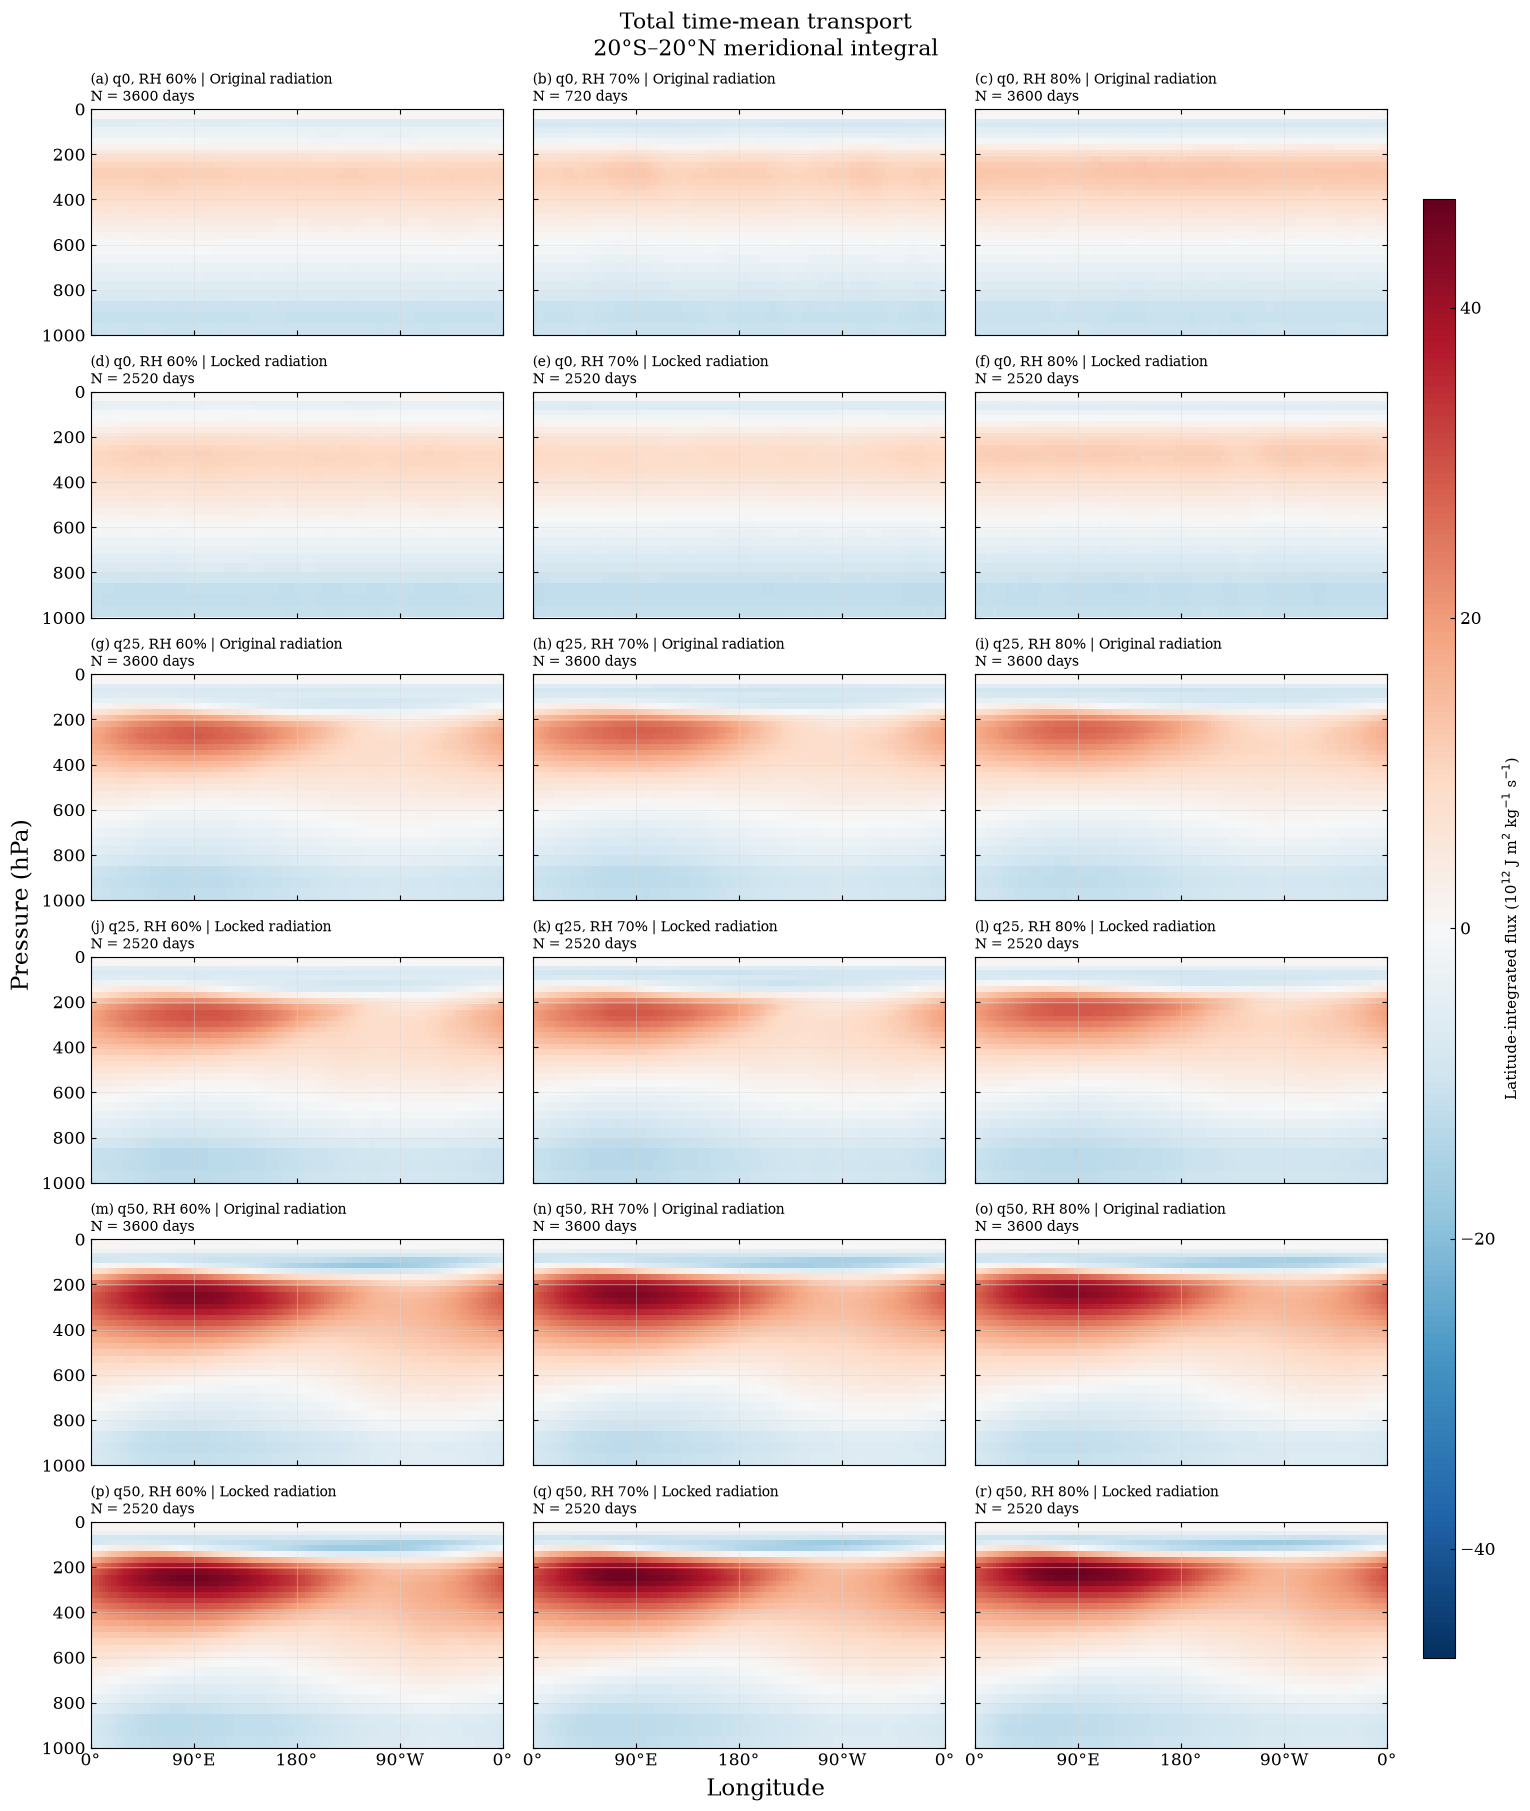

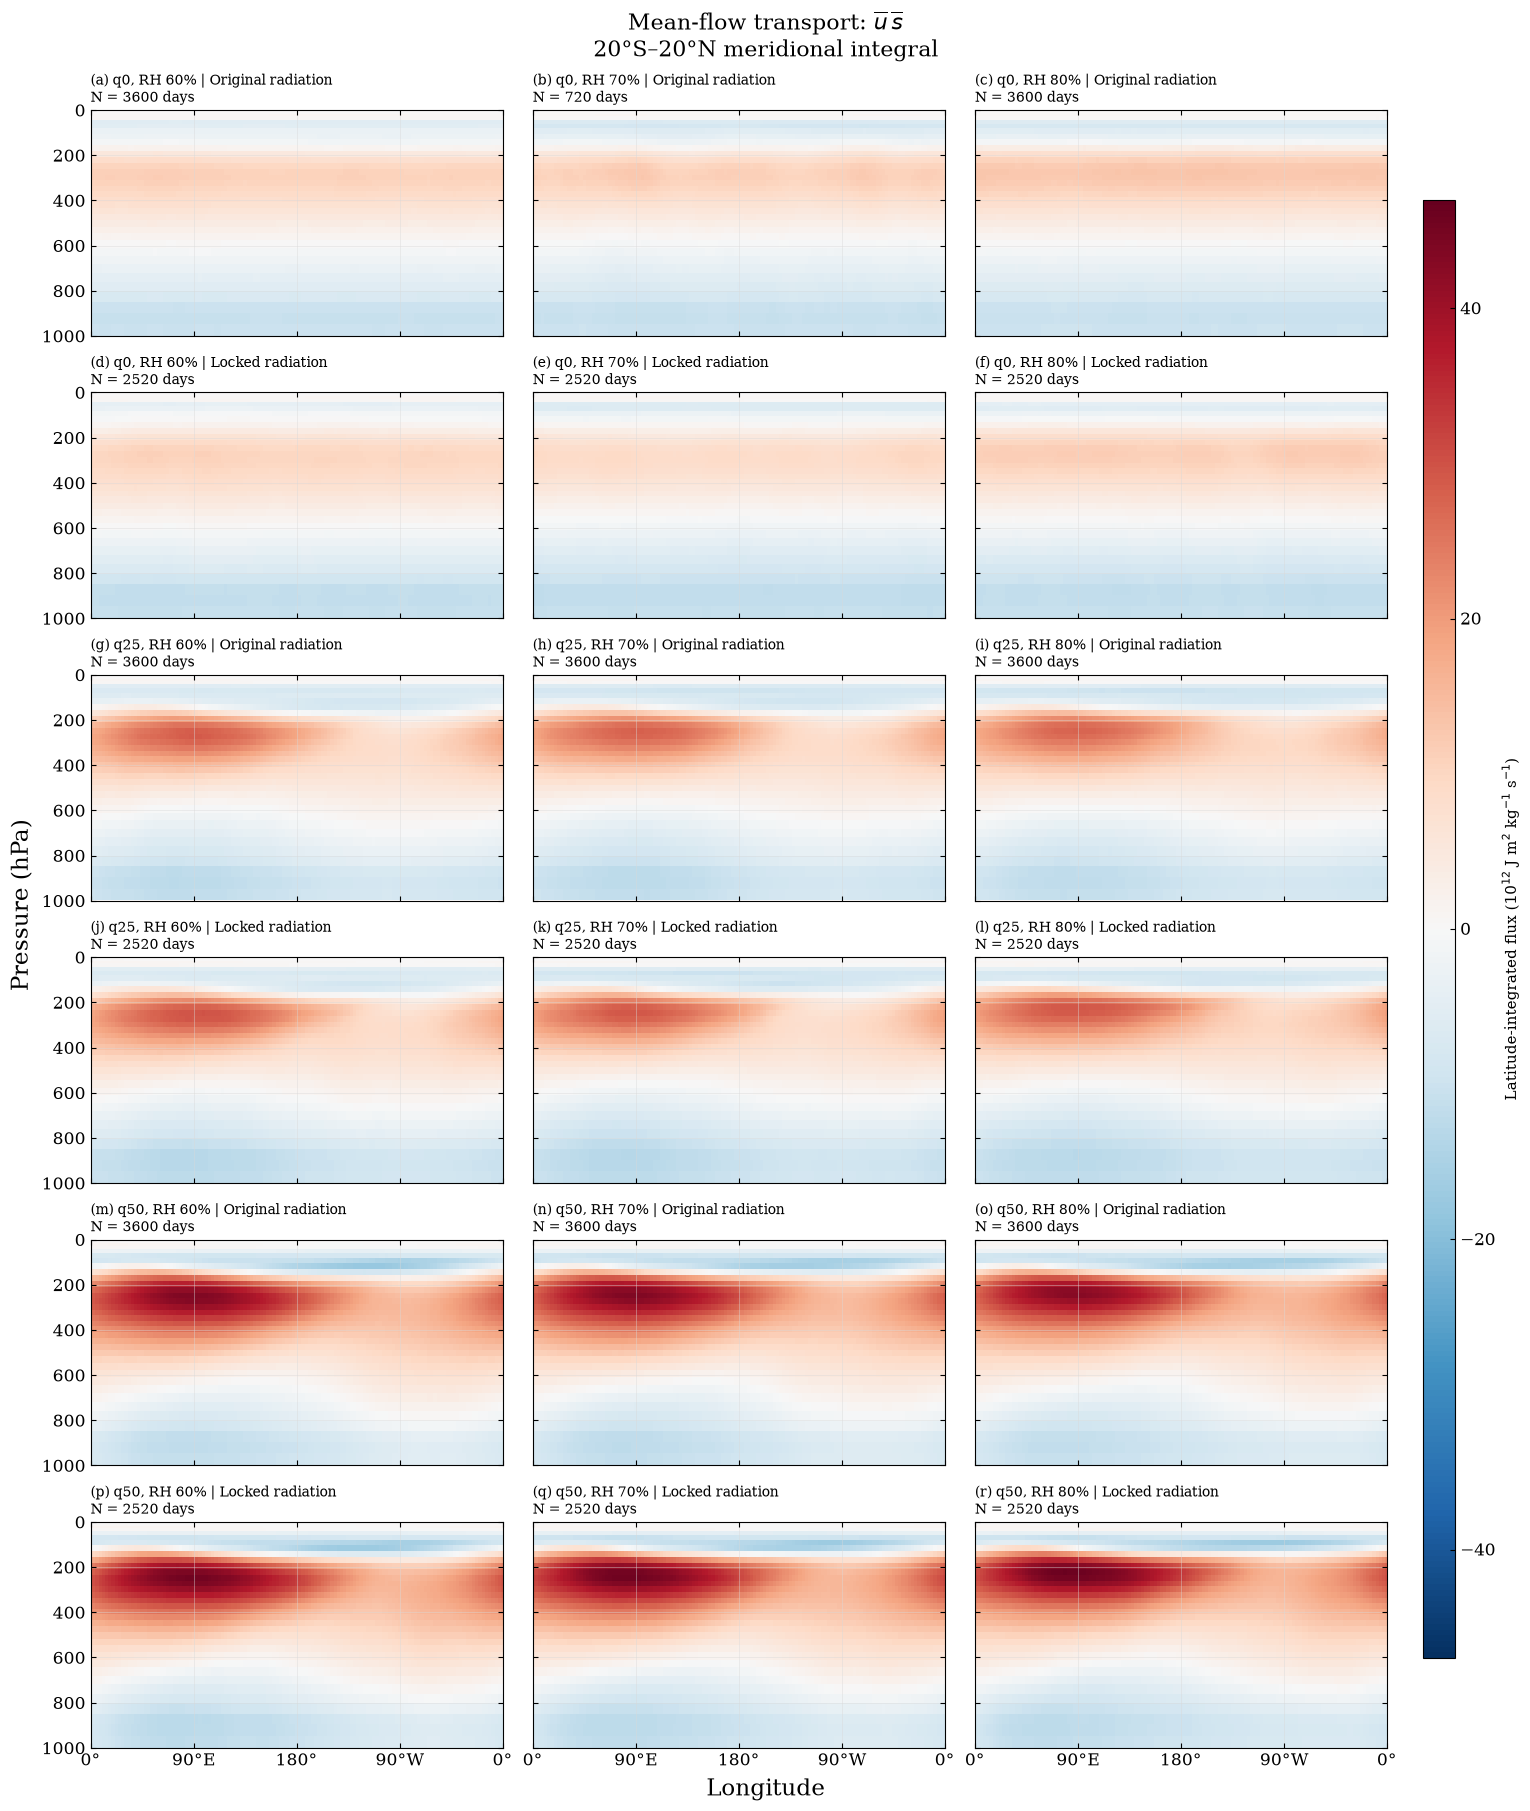

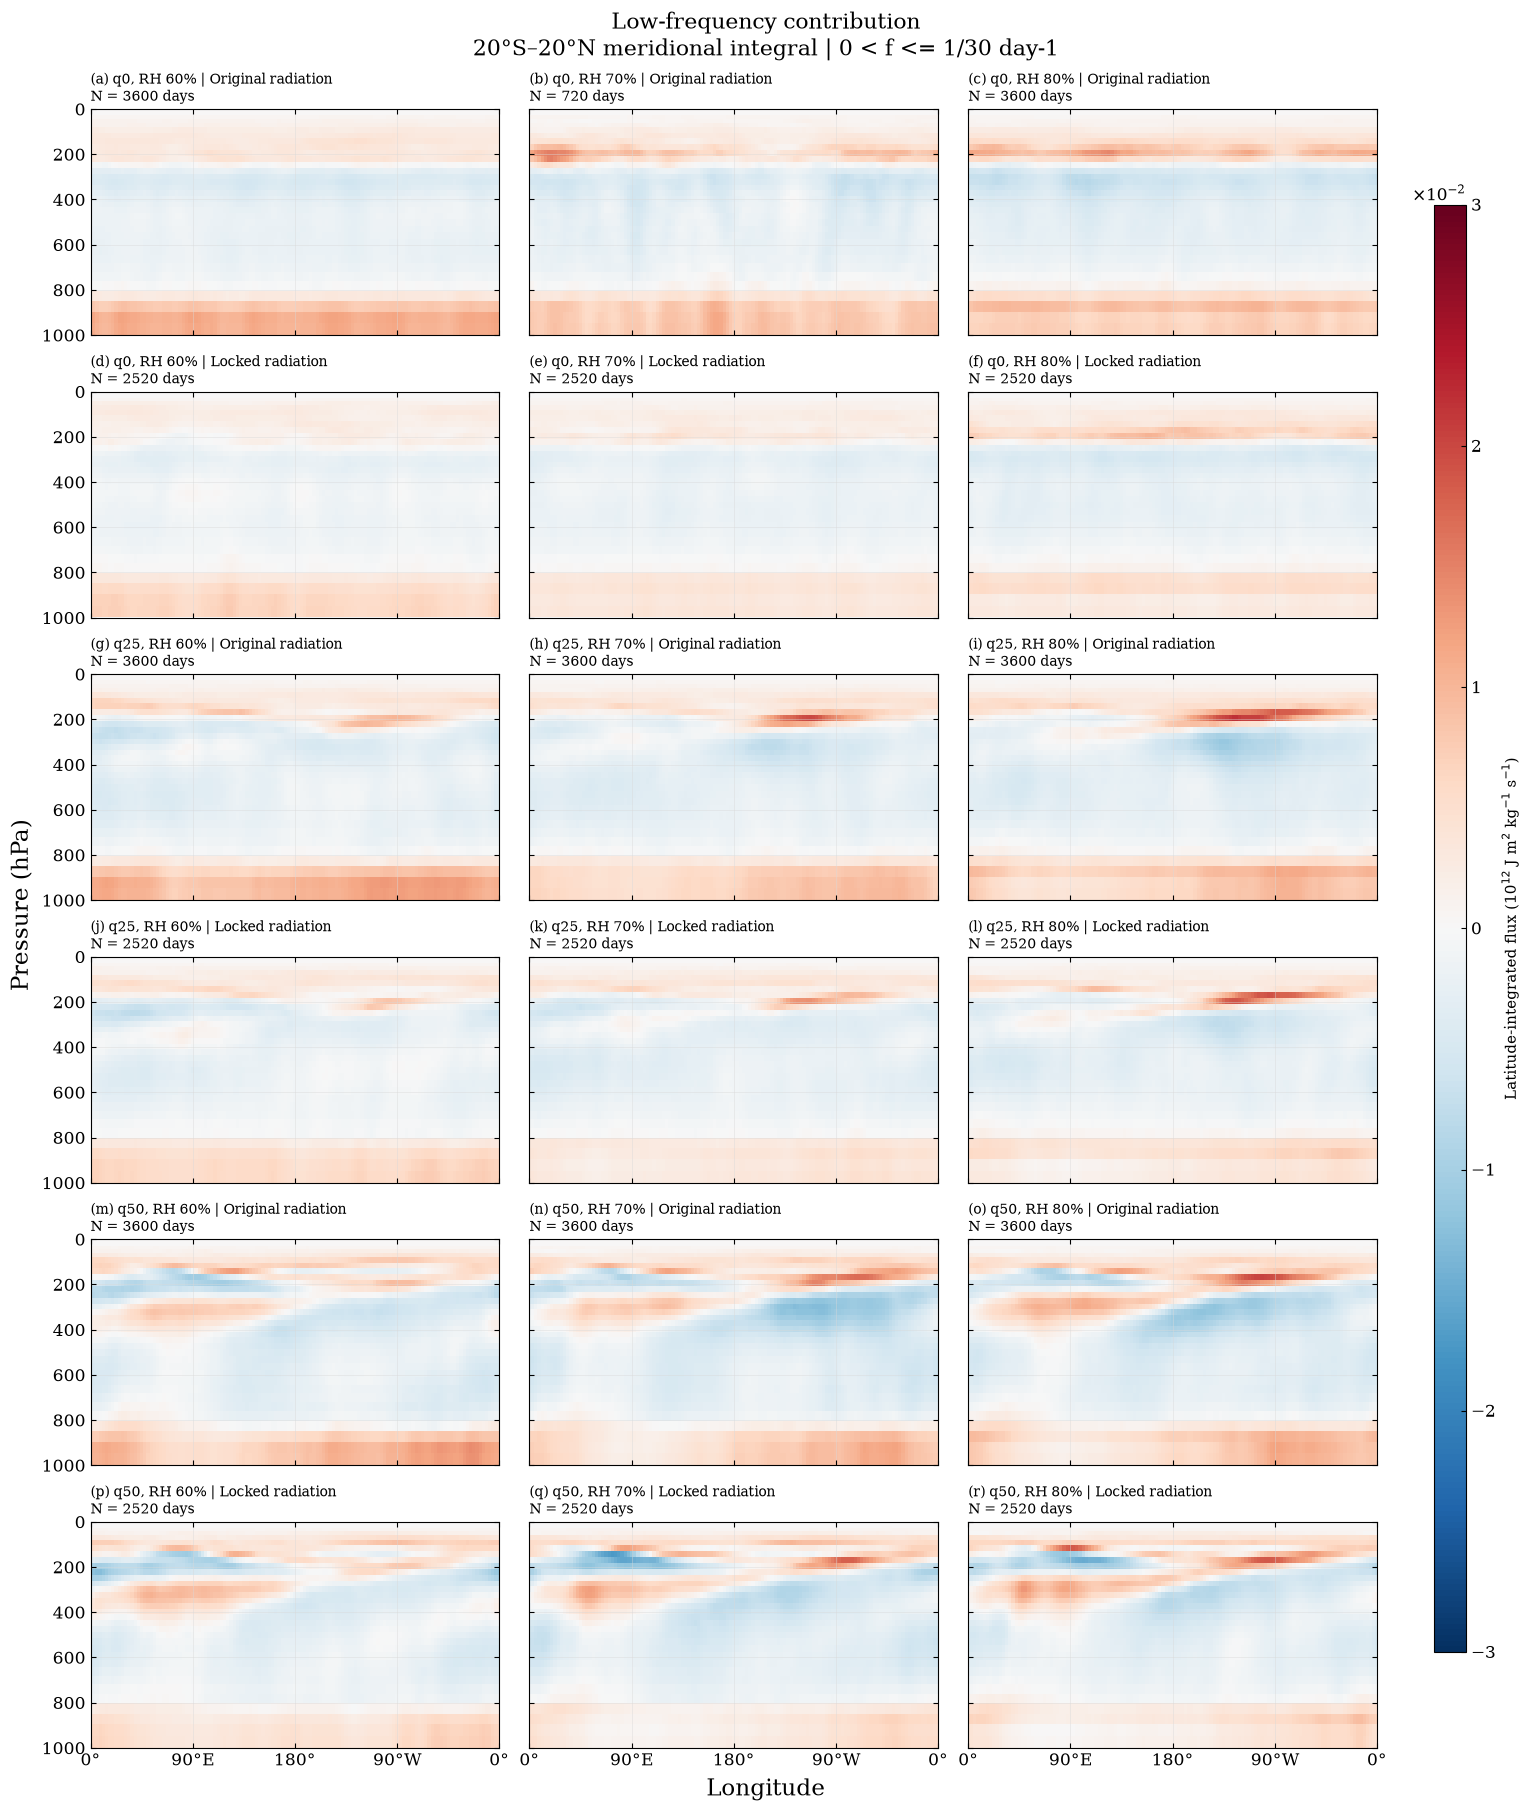

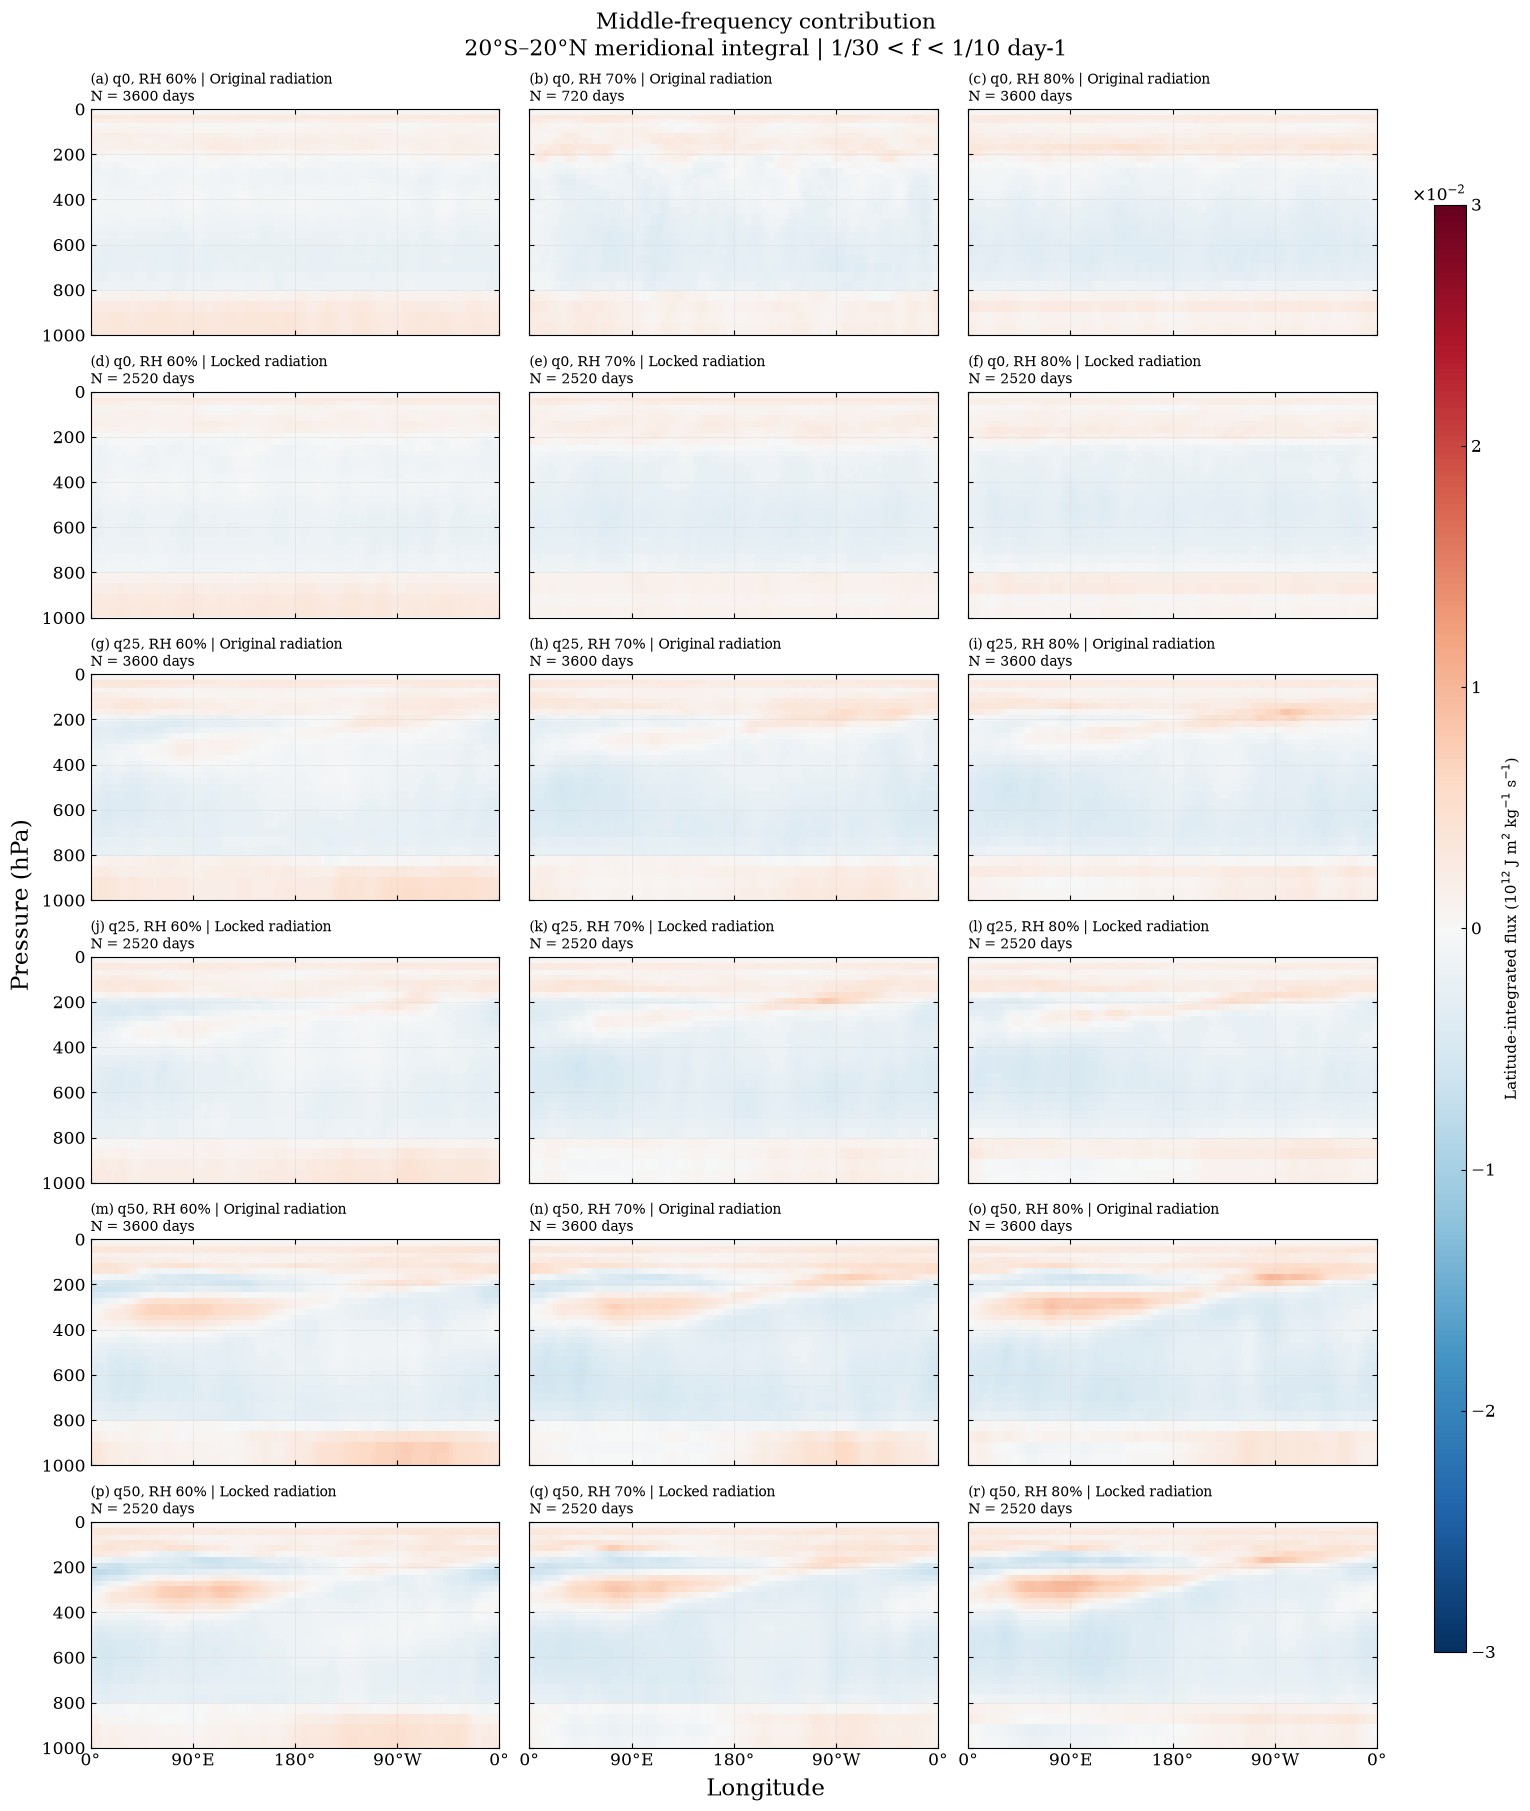

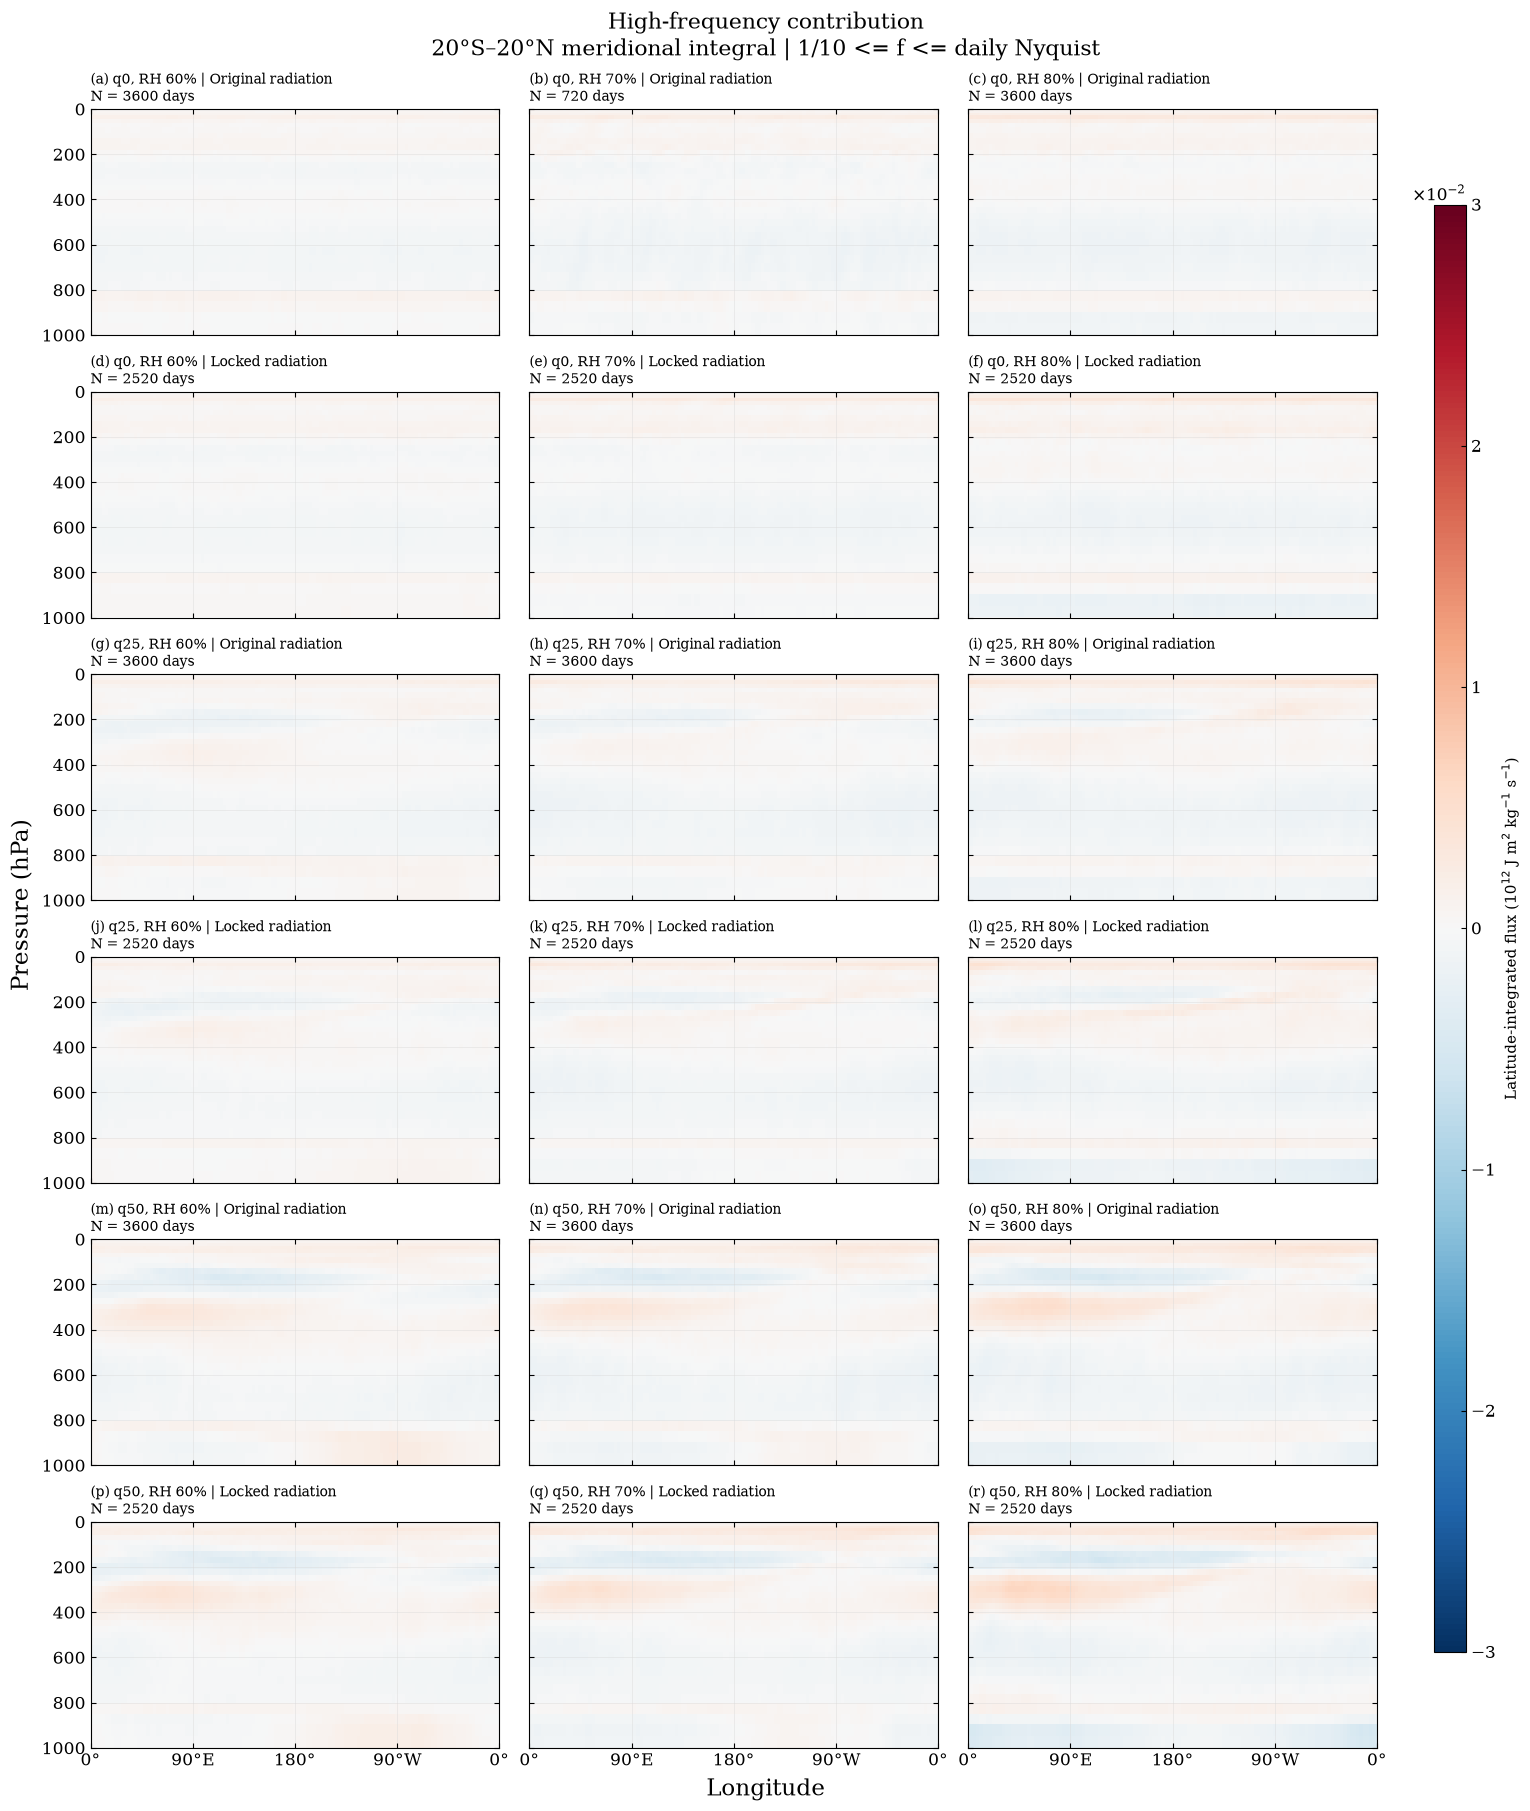

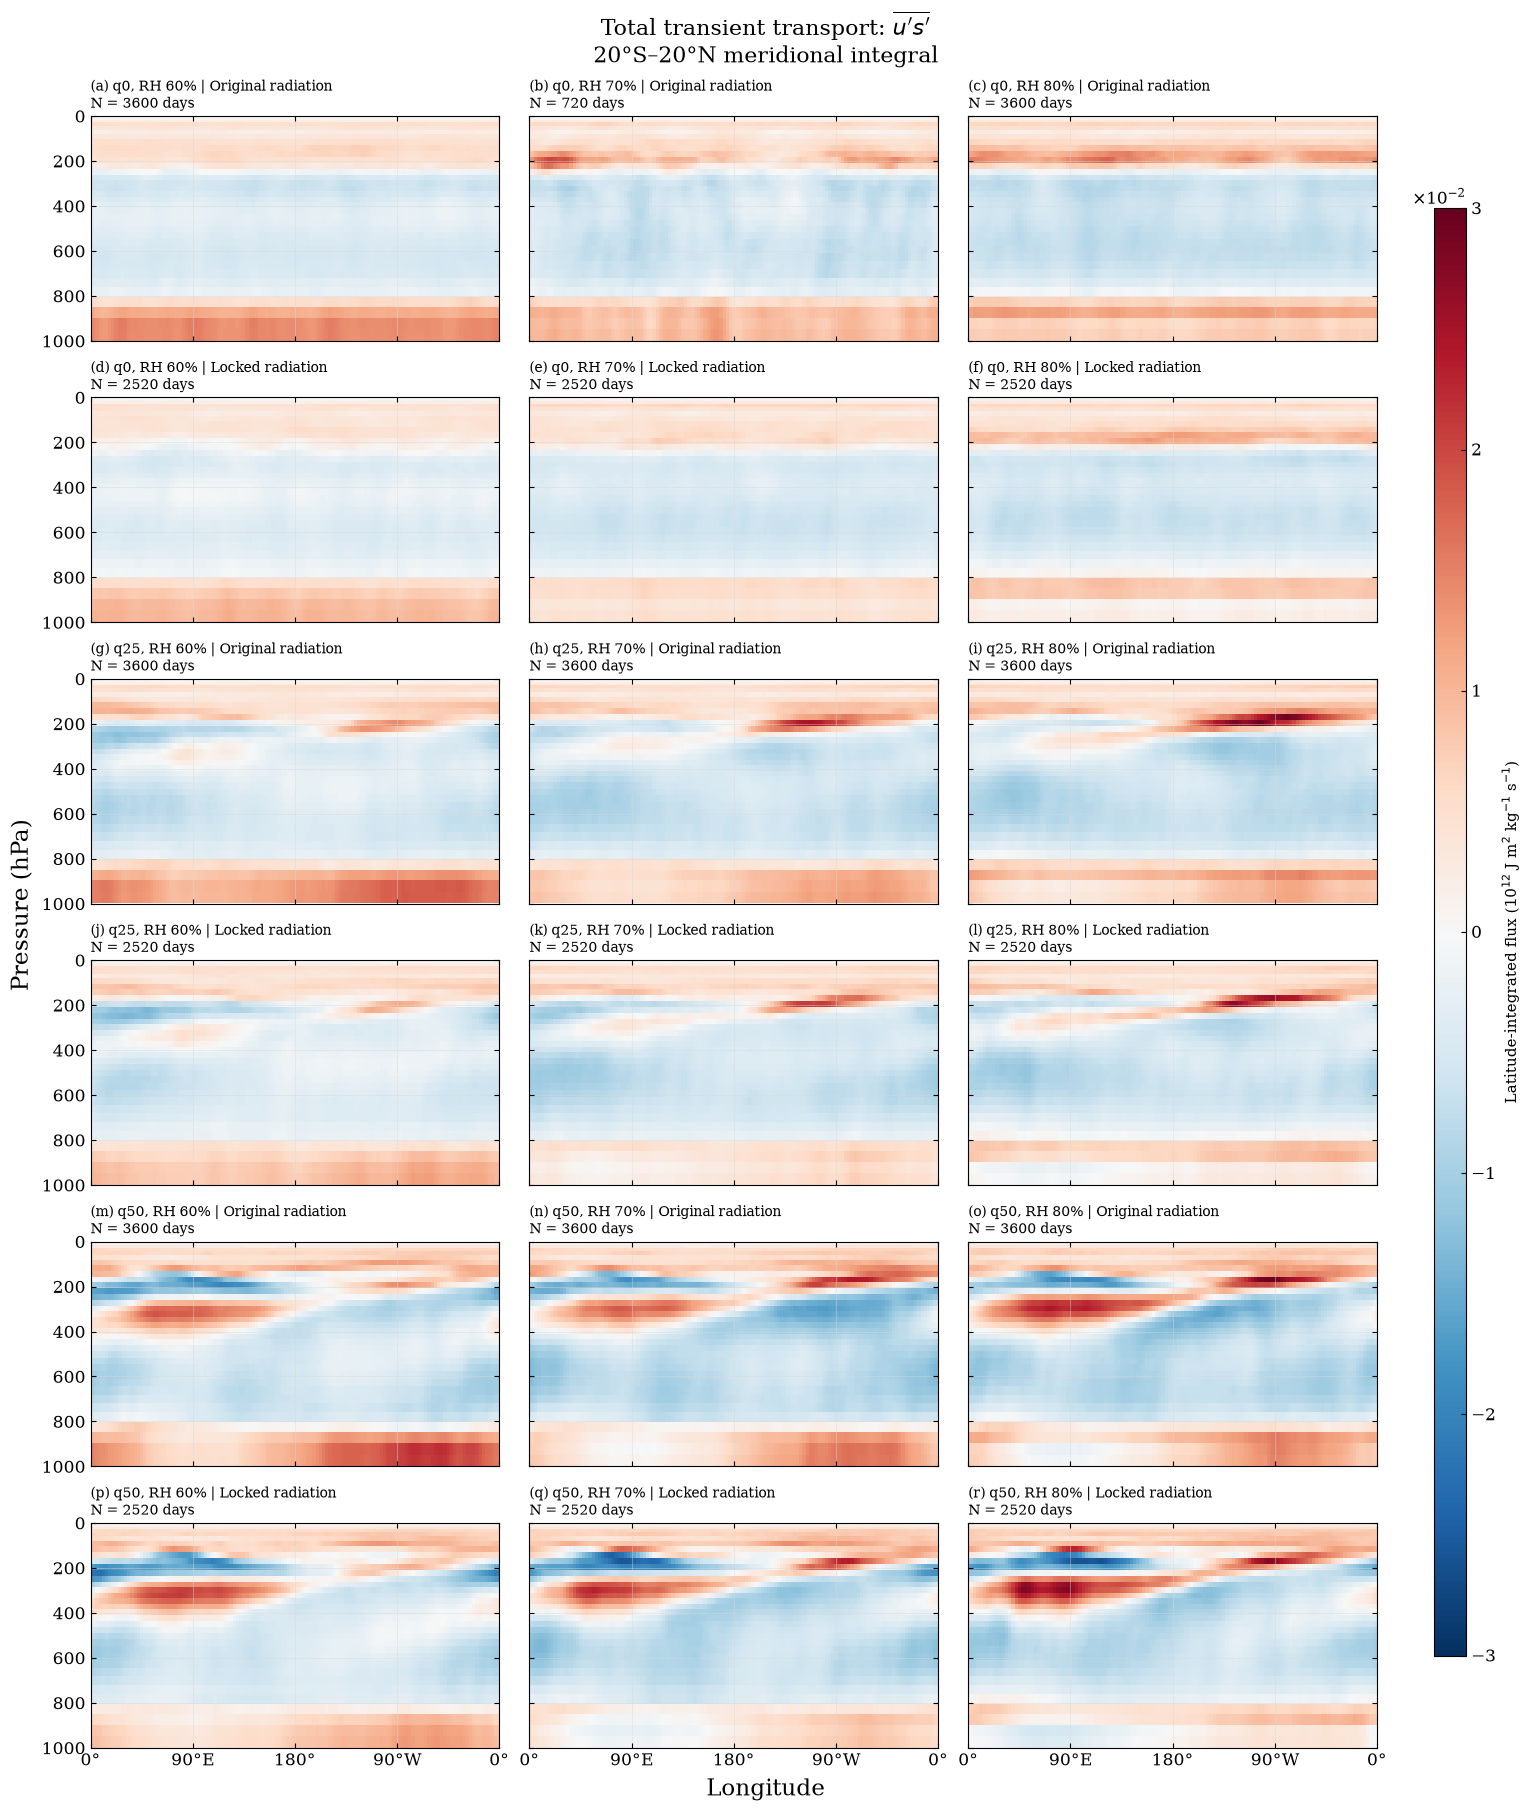

In [15]:
if PLOT_MAPS:
    mean_norm = map_normalization(("total", "mean_flow"), MEAN_MAP_LIMIT)
    transient_norm = map_normalization(("low", "mid", "high", "transient"), TRANSIENT_MAP_LIMIT)
    for field in FIELD_NAMES:
        norm = mean_norm if field in ("total", "mean_flow") else transient_norm
        figures[f"{field}_comparison"] = plot_map_grid(field, norm)


## Overall and frequency-band contribution bars

The overall-budget figure shows total, mean-flow, and transient transport in PW.
The frequency figure expands the transient budget into low, middle, high,
cross, and net transient contributions in TW. One PW equals 1000 TW.
Each figure has a common vertical scale across all experiments.

Cross terms sum all off-diagonal products, including mean-band products.
Hatched totals are reference sums of their components.


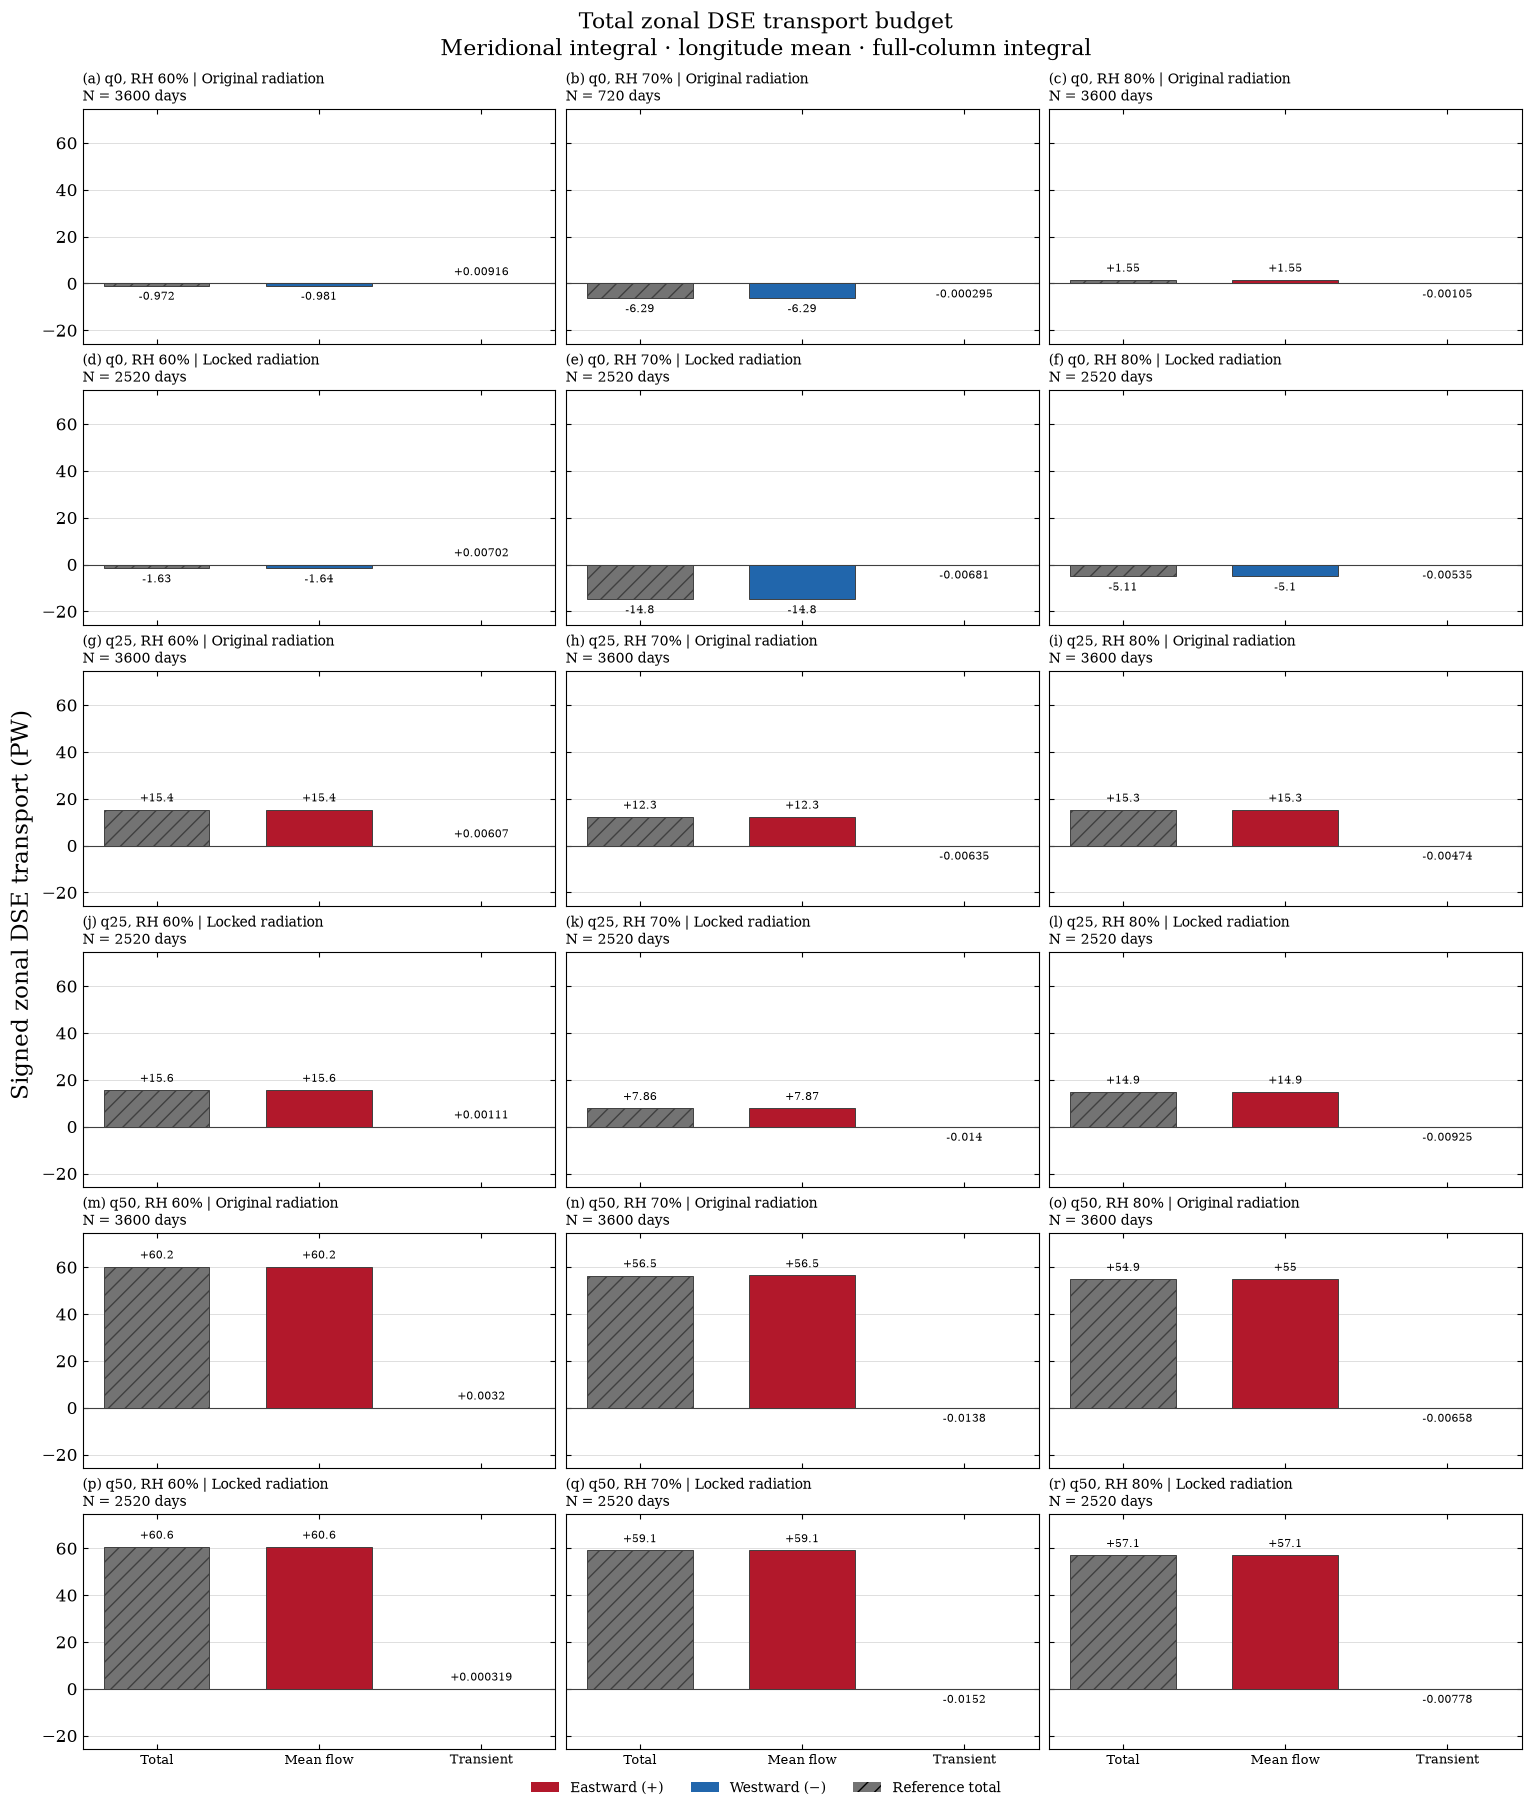

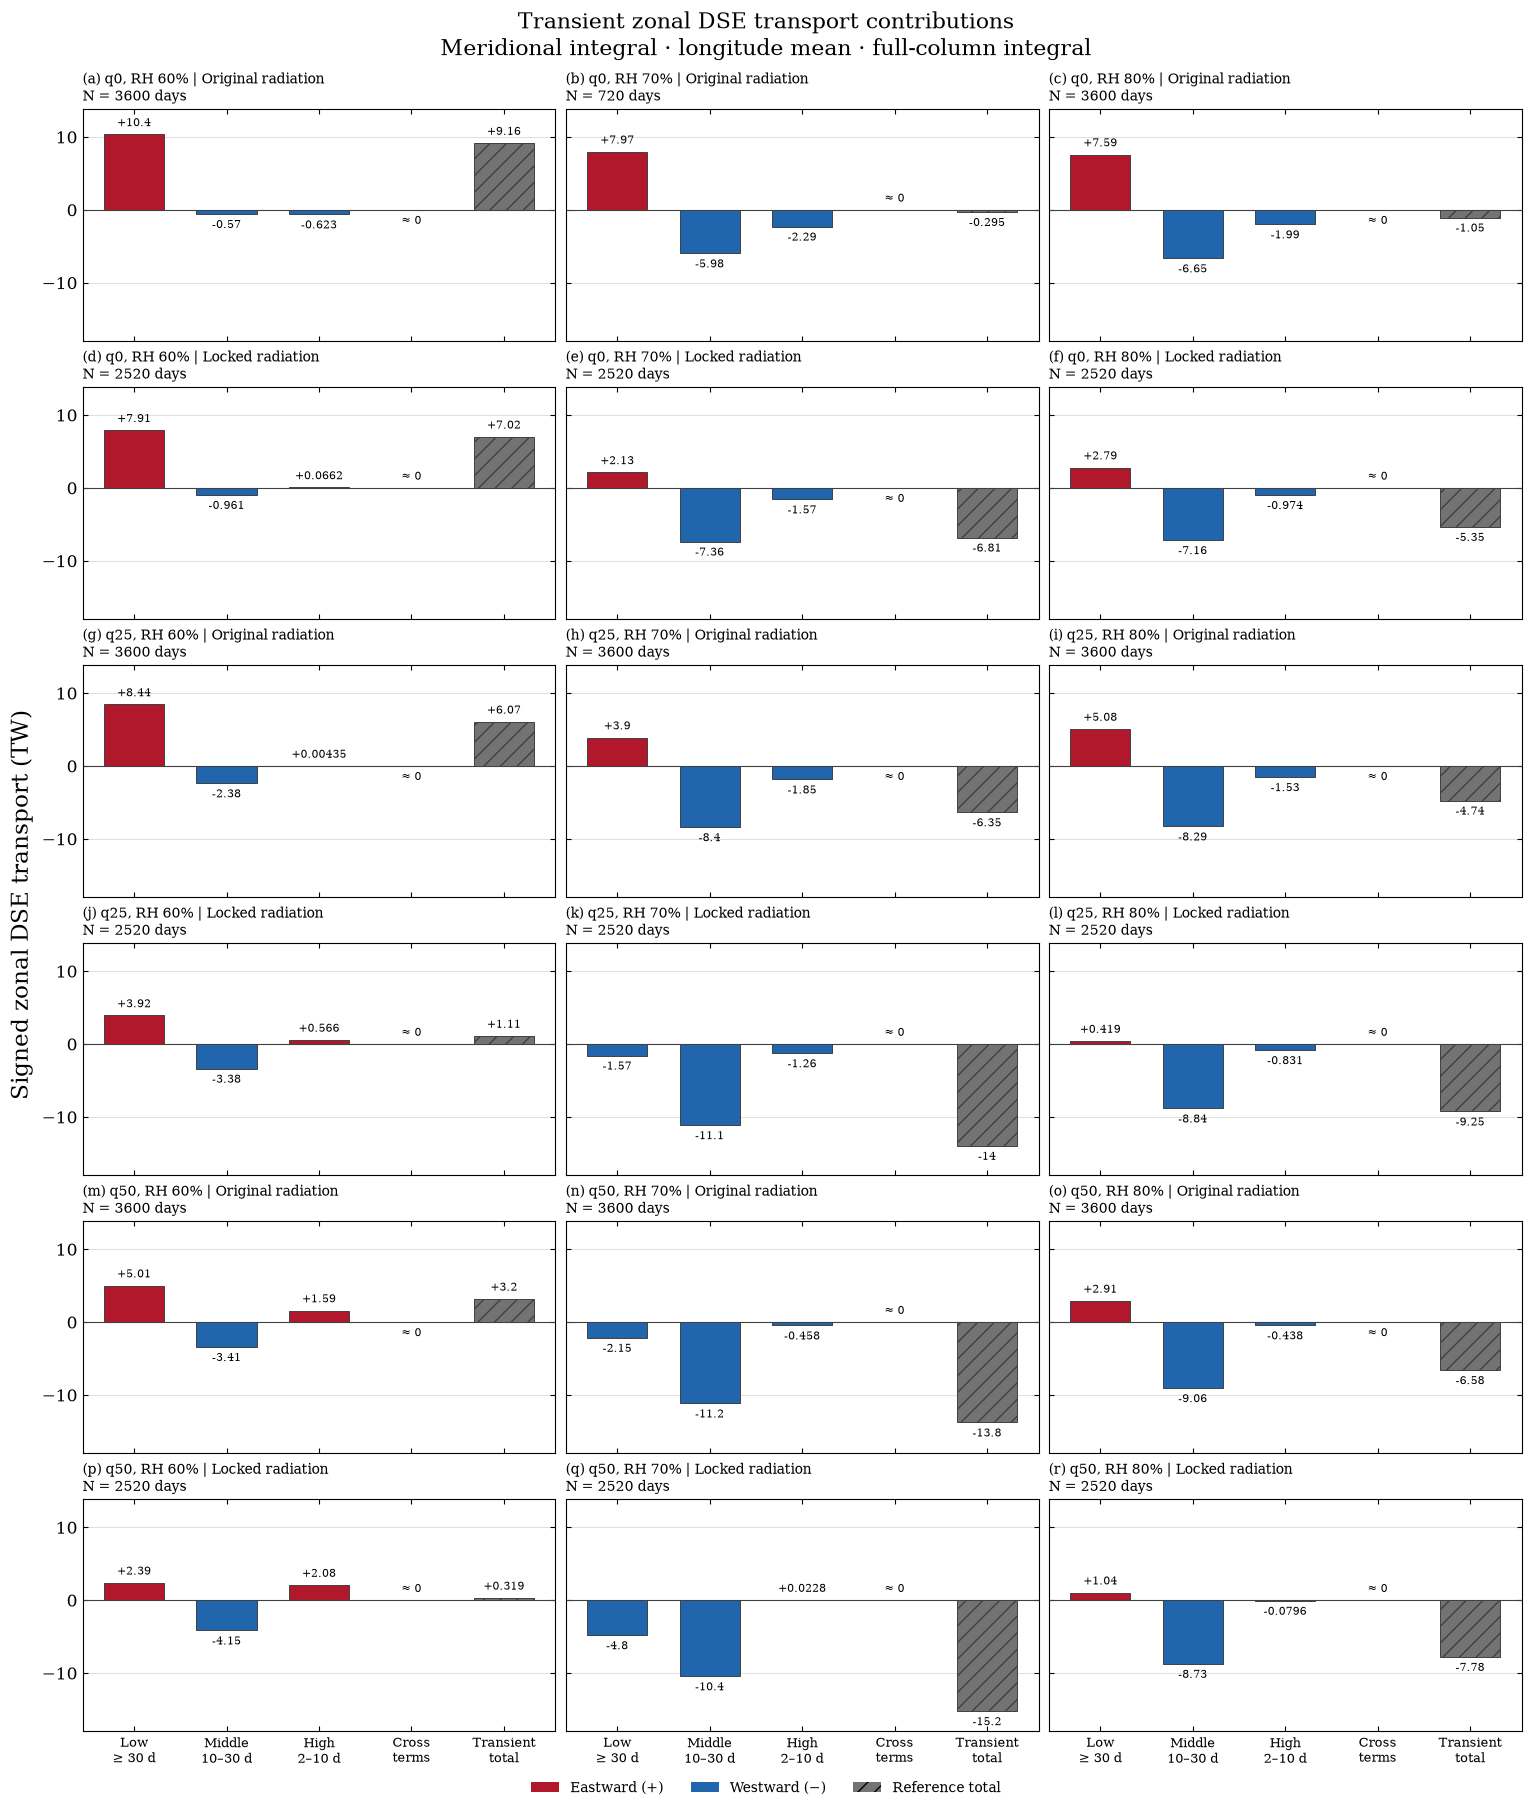

In [16]:
if PLOT_BARS:
    figures["budget_bars_comparison"] = plot_bar_grid(
        ("total", "mean_flow", "transient"), ["Total", "Mean flow", "Transient"],
        1e15, "PW", BUDGET_BAR_LIMITS, "Total zonal DSE transport budget",
    )
    figures["frequency_bars_comparison"] = plot_bar_grid(
        ("low", "mid", "high", "cross", "transient"), BAND_LABELS,
        1e12, "TW", TRANSIENT_BAR_LIMITS, "Transient zonal DSE transport contributions",
    )


## Collected numerical contributions

The table contains the exact saved-budget contributions, their averaging
periods, and source files. Bar annotations are rounded only for display.
All quantities are signed: positive eastward, negative westward.


In [17]:
display(summary_table[[
    "retained_days", "total_PW", "mean_flow_PW", "transient_TW",
    "low_TW", "mid_TW", "high_TW", "cross_W",
]].style.format({
    "total_PW": "{:+.4f}", "mean_flow_PW": "{:+.4f}",
    "transient_TW": "{:+.4f}", "low_TW": "{:+.4f}",
    "mid_TW": "{:+.4f}", "high_TW": "{:+.4f}", "cross_W": "{:+.3e}",
}))


,retained_days,total_PW,mean_flow_PW,transient_TW,low_TW,mid_TW,high_TW,cross_W
experiment,,,,,,,,
q0_rh60_boriginal,3600,-0.9715,-0.9807,+9.1627,+10.3558,-0.5701,-0.6229,-1.459e-03
q0_rh70_boriginal,720,-6.2901,-6.2898,-0.2952,+7.9731,-5.9752,-2.2931,+8.446e-04
q0_rh80_boriginal,3600,+1.5486,+1.5497,-1.0544,+7.5853,-6.6511,-1.9886,-4.421e-03
q0_rh60_b_lock,2520,-1.6339,-1.6409,+7.0168,+7.9114,-0.9608,+0.0662,+1.427e-03
q0_rh70_b_lock,2520,-14.8435,-14.8367,-6.8082,+2.1303,-7.3636,-1.5749,-3.009e-02
q0_rh80_b_lock,2520,-5.1064,-5.1011,-5.3471,+2.7892,-7.1620,-0.9742,+3.743e-02
q25_rh60_boriginal,3600,+15.3623,+15.3562,+6.0669,+8.4401,-2.3776,+0.0044,-3.214e-04
q25_rh70_boriginal,3600,+12.2615,+12.2679,-6.3482,+3.8965,-8.3973,-1.8474,-1.035e-03
q25_rh80_boriginal,3600,+15.2648,+15.2695,-4.7433,+5.0758,-8.2932,-1.5259,-4.143e-04


## Optional comparison-figure and summary export

Enable either switch to save the comparison figures at 300 dpi or the collected
table as CSV. The figure collection uses its own **Comparison** subfolder.
Source experiment budgets are read only.


In [18]:
SAVE_FIGURES = True
SAVE_SUMMARY = True
FIGURE_DIR = PROJECT_ROOT / "Figure" / "Zonal_energy_transpose" / "Comparison"
SUMMARY_PATH = DATA_DIR / "component_contributions_comparison.csv"

if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    for name, figure in figures.items():
        output_path = FIGURE_DIR / f"{name}.png"
        figure.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"Saved {output_path}")

if SAVE_SUMMARY:
    summary_table.to_csv(SUMMARY_PATH, index_label="experiment")
    print(f"Saved {SUMMARY_PATH}")


Saved /home/b11209013/Isca_analysis/Figure/Zonal_energy_transpose/Comparison/total_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/Zonal_energy_transpose/Comparison/mean_flow_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/Zonal_energy_transpose/Comparison/low_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/Zonal_energy_transpose/Comparison/mid_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/Zonal_energy_transpose/Comparison/high_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/Zonal_energy_transpose/Comparison/transient_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/Zonal_energy_transpose/Comparison/budget_bars_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/Zonal_energy_transpose/Comparison/frequency_bars_comparison.png
Saved /home/b11209013/Isca_analysis/Output/Zonal_energy_transpose/component_contributions_comparison.csv


## Reading these comparisons

The spatial mean-flow map can show eastward and westward branches whose
column integrals cancel partly. The bar plots report the signed residual
after column integration and longitude averaging. Small net transient
transport can therefore coexist with substantial local contributions.

Transport direction does not identify the propagation direction of the
disturbances. Cross-band products are close to zero for disjoint Fourier
bands averaged over the complete saved record.
